In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F

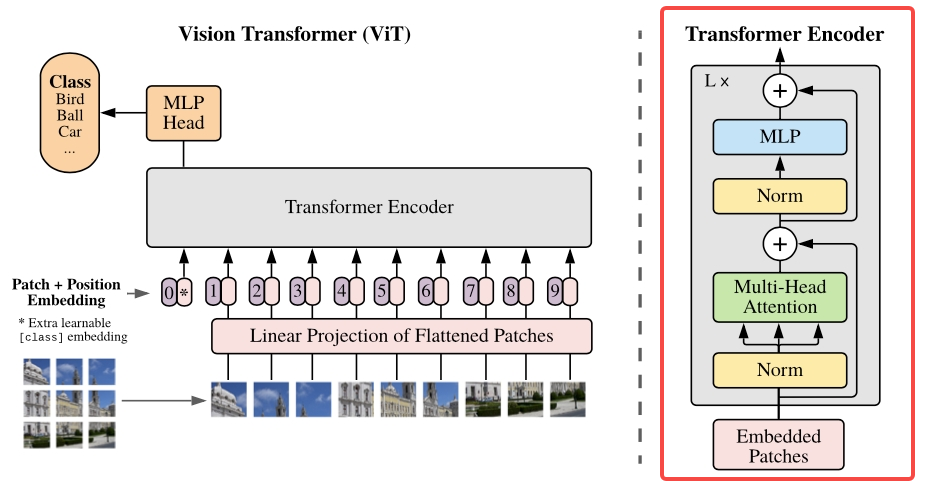

In [3]:
class MultiheadSelfAttention(nn.Module):
    def __init__(self, dim, num_heads, p_drop):
        super().__init__()
        self.dim = dim
        self.num_heads = num_heads
        
        self.qkv_proj = nn.Linear(dim, 3*dim)
        self.out_proj = nn.Linear(dim, dim)
        self.drop_out = nn.Dropout(p_drop)
        
        # mask = torch.tril(torch.ones(max_len, max_len))
        # self.register_buffer('mask', mask.reshape(1, 1, max_len, max_len))
        
    def forward(self, x):
        q, k, v = self.qkv_proj(x).split(self.dim, dim=-1)
        
        B, L, D = q.shape
        q = q.reshape(B, L, self.num_heads, D // self.num_heads).transpose(1, 2)
        k = k.reshape(B, L, self.num_heads, D // self.num_heads).transpose(1, 2)
        v = v.reshape(B, L, self.num_heads, D // self.num_heads).transpose(1, 2)

        attn = (q @ k.transpose(-1, -2)) / torch.tensor([k.size(-1)]).sqrt().to(k.device)
        # attn.masked_fill_(self.mask[:,:,:L,:L]==0, value=-100000)
        attn = F.softmax(attn, dim=-1)
        
        out = attn @ v
        out = out.transpose(1, 2).reshape(B, L, D)
        out = self.out_proj(out)
        out = self.drop_out(out)

        return out

class MLP(nn.Module):
    def __init__(self, dim, h_dim, p_drop=0.1):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(dim, h_dim),
            nn.ReLU(),
            nn.Dropout(p_drop),
            nn.Linear(h_dim, dim),
        )

    def forward(self, x):
        return self.model(x)

class TransformerEncoderBlock(nn.Module):
    def __init__(self, dim, ffn_dim, num_heads, p_drop):
        super().__init__()
        self.attn = MultiheadSelfAttention(dim, num_heads, p_drop)
        self.mlp = MLP(dim, ffn_dim, p_drop)
        self.norm1 = nn.LayerNorm(dim)
        self.norm2 = nn.LayerNorm(dim)

    def forward(self, x):
        x = x + self.attn(self.norm1(x)) # x = self.norm1(x + self.attn(x))
        x = x + self.mlp(self.norm2(x)) # x = self.norm2(x + self.ffn(x))
        return x

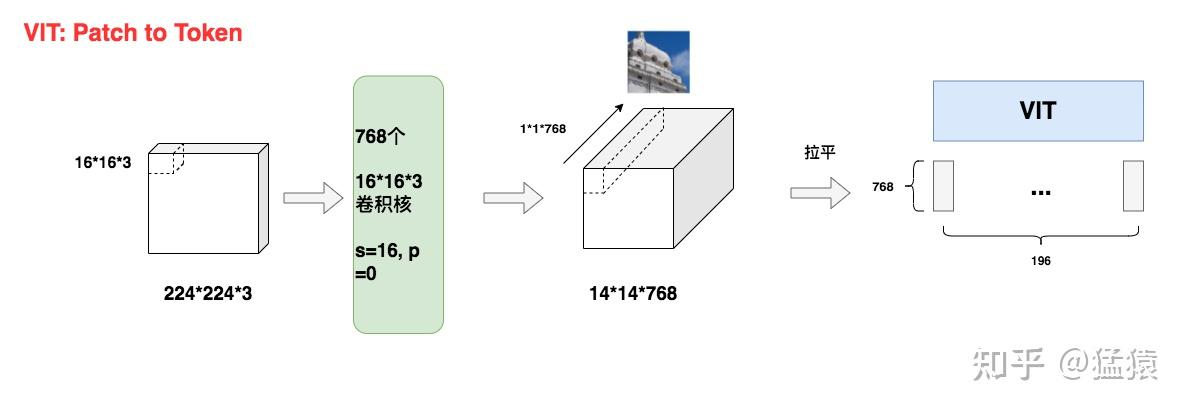

In [4]:
class PatchEmbedding(nn.Module):
    def __init__(self, img_size, patch_size, in_channels, embed_dim):
        super().__init__()
        assert img_size % patch_size == 0 # num_patches = (img_size // patch_size) ** 2 
        self.img_shape = torch.Size([in_channels, img_size, img_size])
        self.conv = nn.Conv2d(
            in_channels = in_channels,
            out_channels = embed_dim,
            kernel_size = patch_size,
            padding = 0,
            stride = patch_size,
        )
    
    def forward(self, x):
        assert x.shape[-3:] == self.img_shape # [(B,) C, H, W]
        x = self.conv(x)                      # [(B,) embed_dim, H/P, W/P]
        x = x.flatten(2).transpose(1, 2)      # [(B,) num_patches, embed_dim]
        return x

In [5]:
def test1():
    PE = PatchEmbedding(img_size=224, patch_size=16, in_channels=3, embed_dim=768)
    imgs = torch.rand(1, 3, 224, 224)
    pe = PE(imgs)
    print(pe.shape)

test1()

torch.Size([1, 196, 768])


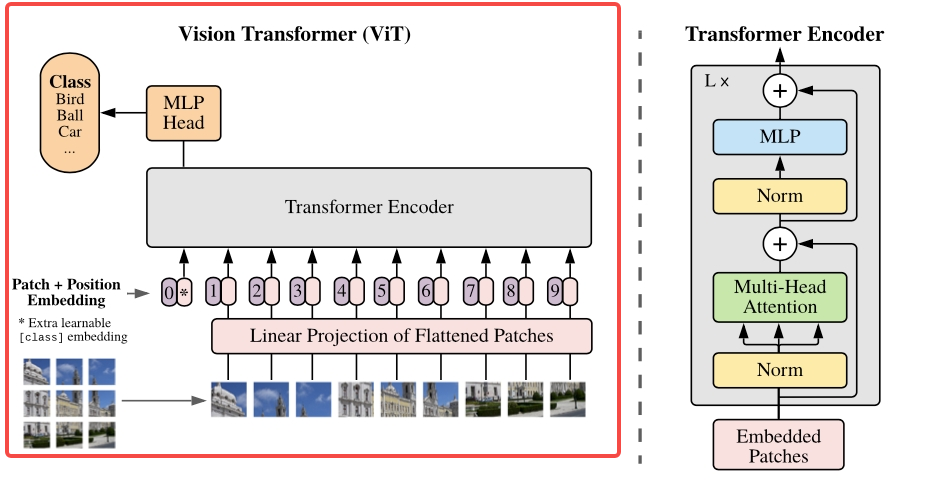

In [6]:
class PositionEmbedding(nn.Embedding):
    def __init__(self, *args, **kargs):
        super().__init__(*args, **kargs)

    def forward(self, x):
        assert x.shape[-2:] == self.weight.shape
        l = x.size(-2)
        indeces = torch.arange(l).expand(*x.shape[:-2], l).to(x.device)
        # print(indeces[...,:10])
        return super().forward(indeces)

In [7]:
def test2():
    PE = PositionEmbedding(num_embeddings=196, embedding_dim=768)
    imgs = torch.rand(1, 196, 768)
    pe = PE(imgs)
    print(pe.shape)

test2()

torch.Size([1, 196, 768])


In [13]:
class ViT(nn.Module):
    def __init__(
        self,
        img_size,
        patch_size,
        in_channels,
        dim,
        ffn_dim,
        num_heads,
        num_layers,
        num_classes,
        p_drop
    ):
        super().__init__()
        num_patches = (img_size // patch_size) ** 2 

        self.encoder = nn.Sequential(
            *[TransformerEncoderBlock(dim, ffn_dim, num_heads, p_drop) for _ in range(num_layers)]
        )
        self.position_emb = PositionEmbedding(num_patches + 1, dim) # add [cls]
        self.patch_emb = PatchEmbedding(img_size, patch_size, in_channels, dim)
        self.classifier = nn.Linear(dim, num_classes)

        self.cls_token = nn.Parameter(torch.rand(1, dim))

    ### init method, copy from `model.py` in mingpt project, but works quitely bad here. 
    #     self.apply(self._init_weights)
    
    # def _init_weights(self, module):
    #     if isinstance(module, nn.Linear):
    #         torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
    #         if module.bias is not None:
    #             torch.nn.init.zeros_(module.bias)
    #     elif isinstance(module, nn.Embedding):
    #         torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
    #     elif isinstance(module, nn.LayerNorm):
    #         torch.nn.init.zeros_(module.bias)
    #         torch.nn.init.ones_(module.weight)
    
    def forward(self, x):
        x = self.patch_emb(x) # [(batch,) num_patches, dim]
        
        cls = self.cls_token.expand(*x.shape[:-2], 1, x.size(-1))
        x = torch.cat([cls, x], dim=-2) # add [cls]
        
        x = x + self.position_emb(x)
        x = self.encoder(x)

        return self.classifier(x[..., 0, :])

In [9]:
def test3():
    vit = ViT(
        img_size = 28,
        patch_size = 4,
        in_channels = 1,
        dim = 16,
        ffn_dim = 32,
        num_heads = 2,
        num_layers = 3,
        num_classes = 10,
        p_drop = 0
    )

    imgs = torch.randn(5, 1, 28, 28)
    print(vit(imgs).shape)

test3()

torch.Size([5, 10])


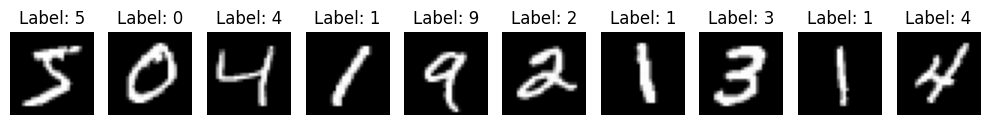

In [ ]:
from torchvision import datasets, transforms

transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
train_data = datasets.MNIST(root="~/.cache/", transform=transform, train=True, download=True)
test_data = datasets.MNIST(root="~/.cache/", transform=transform, train=False)

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 10, figsize=(10, 2))
for i in range(10):
    image, label = test_data[i]
    ax = axes[i]
    ax.imshow(image[0], cmap='gray')
    logits = vit(image.unsqueeze(0).to(device))
    ax.set_title(f'T/P: {label}/{logits.argmax(-1).item()}')
    ax.axis('off')

plt.tight_layout()
plt.show()

In [11]:
class EMALoss():
    def __init__(self, alpha):
        super().__init__()
        # 更新权重
        self.alpha = alpha
        self.loss = None

    def reset(self):
        self.loss = None

    def update(self, loss):
        if self.loss is None:
            self.loss = loss.item()
        else:
            self.loss = self.alpha * loss.item() + (1 - self.alpha) * self.loss
    
    def item(self):
        return self.loss

In [15]:
from torch.utils.data import DataLoader
from tqdm import tqdm

torch.cuda.empty_cache()

num_epoch = 60
batch_size = 1024
lr = 1e-3
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
vit = ViT(
    img_size = 28,
    patch_size = 4,
    in_channels = 1,
    dim = 16,
    ffn_dim = 32,
    num_heads = 2,
    num_layers = 3,
    num_classes = 10,
    p_drop = 0.0
).to(device) # suit MNIST only

train_loader = DataLoader(train_data, batch_size=batch_size, num_workers=8, persistent_workers=True)
test_loader = DataLoader(test_data, batch_size=batch_size, num_workers=8, persistent_workers=True)
optimizer = torch.optim.Adam(vit.parameters(), lr=lr)
ema_loss = EMALoss(alpha=0.9) # for display only
acc = 0

with tqdm(total=(len(train_loader)+len(test_loader))*num_epoch) as pbar:
    for epoch in range(num_epoch):
        pbar.set_description(f'Epoch {epoch + 1}')
        
        # train
        ema_loss.reset()
        vit.train()
        for imgs, labels in train_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            logits = vit(imgs)
            loss = F.cross_entropy(logits, labels)
                
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            ema_loss.update(loss)
            pbar.set_postfix(loss=f'{ema_loss.item():.4f}', acc=f'{acc:.4f}')
            pbar.update(1)

        # eval
        pbar.set_description(f'Eval {epoch + 1}')
        vit.eval()
        with torch.no_grad():
            corr = 0
            for imgs, labels in test_loader:
                imgs, labels = imgs.to(device), labels.to(device)
                logits = vit(imgs)
                corr += torch.sum(logits.argmax(-1) == labels)
                pbar.update(1)
            acc = corr.item() / len(test_data)
            # pbar.set_postfix(acc=f'{acc:2.2f}')

Eval 60: 100%|█████| 4140/4140 [02:16<00:00, 30.25it/s, acc=0.9636, loss=0.0985]


In [16]:
torch.save(vit, 'model.pt')

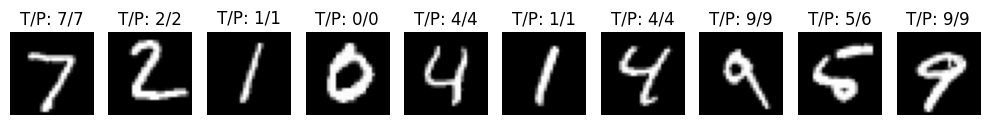

In [ ]:
vit.eval()

image, label = test_data[0]

fig, axes = plt.subplots(1, 10, figsize=(10, 2))
for i in range(10):
    image, label = test_data[i]
    ax = axes[i]
    ax.imshow(image[0], cmap='gray')
    logits = vit(image.unsqueeze(0).to(device))
    ax.set_title(f'T/P: {label}/{logits.argmax(-1).item()}')
    ax.axis('off')

plt.tight_layout()
plt.show()